# Bootstrap references, sample size and training noise

Because of the varying sizes of pairs within the simulations, it becomes important to check if the results are due to the pair mismatch or because of genuine simulation differences.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file())
def table(relative):
    return pd.read_csv(ROOT / 'results' / relative)
def saved_json(relative):
    return json.loads((ROOT / 'results' / relative).read_text(encoding='utf-8'))
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 16)

Three resampling questions enter the argument. A population KS reference compares
TNG-sized FLAMINGO subsets with the remaining FLAMINGO population. A 200-refit
posterior reference includes reduced training sample size and stochastic optimization.
Ten fixed-data fits separately measure training-noise variability. These are distinct
from the final paired component bootstrap and the feature-ablation reference.

### Population KS reference

The subset is drawn **without replacement** and compared with the remaining catalogue.
The recorded observed statistic is 0.3063866; none of 500 repeats reaches it. The
plus-one empirical p value is 1/501, not zero. It addresses the finite-pair-size null
used here, not every possible source of simulation variation.


In [2]:
reference=saved_json('bootstrap/population_reference.json')['theta_marginal']
display(pd.Series(reference,name='Recorded KS reference').to_frame())
assert np.isclose(reference['p_value'],1/501)
# Prior algorithm from npe_bootstrap.ipynb; no NPE refit is needed for this test.
from scipy.stats import ks_2samp
def population_bootstrap(flam_pool,n_target,n_repeats=500,seed=0):
    rng=np.random.default_rng(seed)
    ks_null=np.empty(n_repeats)
    for i in range(n_repeats):
        idx=rng.permutation(len(flam_pool))
        sub=flam_pool[idx[:n_target]]
        rest=flam_pool[idx[n_target:]]
        ks_null[i]=ks_2samp(sub,rest).statistic
    return ks_null

RECOMPUTE_POPULATION_REFERENCE=False
if RECOMPUTE_POPULATION_REFERENCE:
    # Local frames are ignored by Git; generate/import them first.
    f=pd.read_csv(ROOT/'data/frames/flamingo.csv.gz')
    t=pd.read_csv(ROOT/'data/frames/tng.csv.gz')
    null=population_bootstrap(f.log_m200c.to_numpy(),len(t))
    real=ks_2samp(f.log_m200c,t.log_m200c).statistic
    p=(1+np.count_nonzero(null>=real))/(len(null)+1)
    display(pd.Series({'observed_KS':real,'null_mean':null.mean(),'p':p}))

,Recorded KS reference
ks_null_mean,0.021675
ks_null_std,0.006459
ks_real,0.306387
p_value,0.001996
n_tng,1530.000000


### Posterior subsampling and training noise

For each repeat, we train a core-block NPE on 1530 FLAMINGO rows for each of 200 repeats.
JSD compares the conditional posterior at the fixed input with the full FLAMINGO
reference. The block uses a simulation-derived bound mass ratio, so this diagnostic
is not an independent measured Local Group posterior. The finite KDE JSD uses base-2
logarithms with a fixed grid and density floor. Notebook 13's analytic JS in nats is
a separately named diagnostic.


,count,mean,std,min,25%,50%,75%,max
repeat,200.0,99.500000,57.879185,0.000000,49.750000,99.500000,149.250000,199.000000
seed,200.0,2099.500000,57.879185,2000.000000,2049.750000,2099.500000,2149.250000,2199.000000
median,200.0,12.309135,0.030197,12.233313,12.290813,12.308194,12.328052,12.393045
mean,200.0,12.309099,0.030271,12.232468,12.290851,12.308562,12.328451,12.392512
std,200.0,0.138108,0.009059,0.108671,0.131463,0.137511,0.144166,0.163301
jsd_vs_full,200.0,0.032162,0.024430,0.000850,0.014102,0.026353,0.043129,0.124357
jsd_vs_tng,200.0,0.057873,0.033172,0.005458,0.033410,0.050656,0.075373,0.174088
epochs_trained,200.0,56.585000,17.081030,24.000000,46.000000,55.000000,66.000000,121.000000
best_validation_loss,200.0,-0.561663,0.066458,-0.750874,-0.605828,-0.556079,-0.519097,-0.395428


,block,bootstrap_std,training_std,ratio
0,core_dynamics,0.030121,0.018526,0.61506


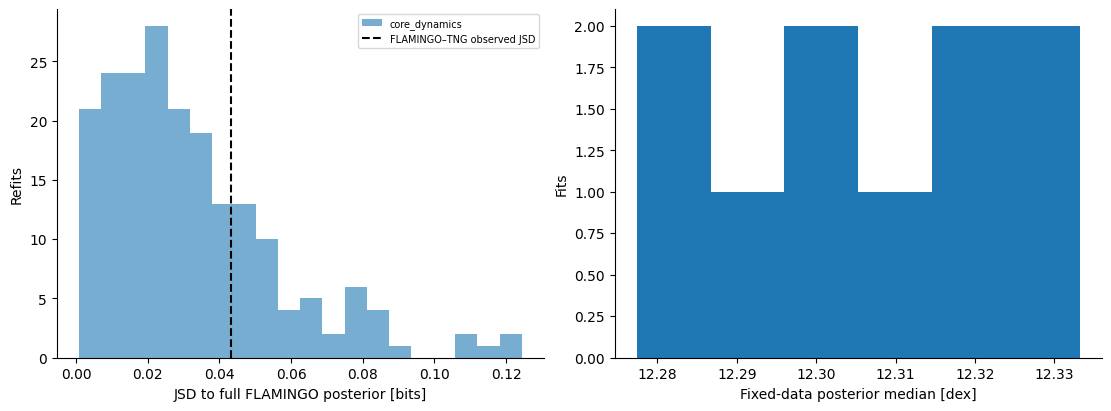

,block,repeats,null_median,null_lower95,null_upper95,observed_jsd,plus_one_p
0,core_dynamics,200,0.026353,0.001902,0.088328,0.043329,0.253731


In [3]:
subs=table('bootstrap/posterior_subsampling_repeats.csv')
noise=table('bootstrap/training_noise_repeats.csv')
observed=saved_json('bootstrap/observed_jsd.json')
display(subs.describe().T)
display(table('bootstrap/noise_comparison.csv'))
rows=[]
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for block,part in subs.groupby('block'):
    value=observed[block]['jsd_full']
    a=part.jsd_vs_full.to_numpy()
    rows.append(dict(block=block,repeats=len(a),null_median=np.median(a),
        null_lower95=np.quantile(a,.025),null_upper95=np.quantile(a,.975),
        observed_jsd=value,plus_one_p=(1+np.count_nonzero(a>=value))/(len(a)+1)))
    axes[0].hist(a,bins=20,alpha=.6,label=block)
    axes[0].axvline(value,color='black',ls='--',label='FLAMINGO–TNG observed JSD')
axes[0].set(xlabel='JSD to full FLAMINGO posterior [bits]',ylabel='Refits');axes[0].legend(fontsize=7)
axes[1].hist(noise.posterior_median,bins=6)
axes[1].set(xlabel='Fixed-data posterior median [dex]',ylabel='Fits');plt.show()
display(pd.DataFrame(rows))
assert len(subs)==200 and len(noise)==10

The **population-mass KS result** exceeds all 500 of its subsampling reference values
(plus-one p = 1/501). The **core-dynamics posterior JSD does not stand out against its
200-refit reference**: the observed JSD is 0.043329 bits, the reference median is
0.026353 bits, and 50 of the 200 refits reach or exceed the observed value. Its plus-one
p value is therefore 51/201 = 0.253731. This diagnostic does not reject sample-size
and training variability as an explanation for the core-dynamics posterior difference.

The feature-ablation W2 experiments have their own 200-refit references. Each observed
ablation discrepancy exceeds its corresponding reference values (p = 1/201; notebook 07).
That feature-specific evidence should not be transferred to the core-dynamics JSD test.
The thesis §5.7 statement about exceeding all 200 references concerns the ablation
experiment. Neither resampling calculation models cosmic variance or identifies a
physical cause.

### Paired component uncertainty

The final-six and normalization comparisons instead resample connected host components
on fixed test rows, using the same component draw for model A and model B. The 2000
repeats preserve pairing and quantify the fitted-model comparison. Their tables are
shown in notebooks 04 and 09. Ablation uses its own 200-refit reference in notebook 07.

Original [sample-size and training-noise workflow](../research/notebooks/original/npe_bootstrap.ipynb),
[population prior checks](../research/notebooks/original/prior-check.ipynb), and
[component resampling](../research/src/lg_npe/final_design.py). Full NPE refits remain
available in the prior notebook; the scalar records above avoid rerunning them.


[Previous](05_calibration.ipynb) · [Next](07_feature_diagnostics_and_ablation.ipynb) · [Repository map](../README.md)
